# REIT Valuation: Funds from Operations, Adjusted FFO and Price Multiples for U.S. REITs from SEC Filings, Implied Cap Rates and Net Asset Value at Property-Type Peer Cap Rates, and Whether NAV Discounts Predict Returns

Real estate investment trusts are valued differently from other companies, and the CFA curriculum's real-estate reading gives three approaches:

- **Funds from operations (FFO)** = net income + real-estate depreciation − gains on property sales. GAAP depreciation understates the value of well-maintained buildings, so REITs and analysts add it back. **Adjusted FFO (AFFO)** subtracts the recurring capital spending needed to keep the properties competitive. Price/FFO and price/AFFO are the sector's P/E ratios.
- **Net asset value (NAV):** value the property portfolio by capitalising its net operating income at a **cap rate**, $V = NOI / \text{cap rate}$, subtract liabilities, and compare with the share price. REITs trade at premiums or discounts to NAV.
- **Discounted cash flow**, not used here.

This notebook applies the first two to U.S. REITs:

1. **Universe and data:** the members of the iShares Core U.S. REIT ETF, their property type, annual financials from SEC company facts (10-K filings, 2012–2025) and prices from Yahoo.
2. **FFO, AFFO and multiples** by property type and over time.
3. **Implied cap rates** (NOI ÷ enterprise value) and a **NAV at the median cap rate of the property type**, giving a premium or discount relative to peers.
4. **Do cheap REITs outperform?** Next-year total returns against NAV discounts, FFO and AFFO yields, leverage and size, with a cross-sectional regression and LightGBM trained on 2013–2018 and tested on 2019–2025.

**Data.** iShares Core U.S. REIT ETF holdings; SEC EDGAR company facts (XBRL); Yahoo Finance (monthly prices); FRED (10-year Treasury yield).

**Methods.** FFO and AFFO construction from XBRL, price multiples, implied cap rates, peer-cap-rate NAV, premium/discount, cross-sectional regression, LightGBM, rank information coefficients, quintile portfolios.

**Key output.** FFO and AFFO multiples and implied cap rates by property type; the distribution of NAV premiums and discounts; and whether they predict returns.

## 1. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import logging
import lightgbm as lgb
import yfinance as yf
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
SEC_HEADERS = {"User-Agent": os.getenv("SEC_USER_AGENT", "").strip()}
if not SEC_HEADERS["User-Agent"]:
    raise RuntimeError(
        "SEC_USER_AGENT missing in .env (the SEC asks automated clients to"
        " identify themselves)."
    )
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}
USRT_URL = (
    "https://www.ishares.com/us/products/239544/fund/latest-holdings.csv"
)
FIRST_FY, LAST_FY = 2012, 2025
TRAIN_LAST = 2018
# Property types of the larger REITs (public classification); others are typed
# from their names or left as "diversified / other"
TYPES = {
    "industrial": "PLD REXR EGP FR STAG TRNO LXP ILPT PLYM COLD IIPR",
    "data centers": "EQIX DLR",
    "towers": "AMT CCI SBAC",
    "health care": "WELL VTR PEAK DOC OHI SBRA NHI CTRE HR MPW LTC",
    "self storage": "PSA EXR CUBE NSA",
    "apartments": "AVB EQR ESS UDR MAA CPT AIV IRT NXRT VRE ELME CSR",
    "single-family and manufactured homes": "INVH AMH ELS SUI",
    "office": "BXP VNO SLG KRC HIW CUZ DEI PDM BDN JBGS OFC CDP EQC HPP PGRE",
    "life science": "ARE",
    "shopping centers and malls": (
        "SPG KIM REG FRT BRX KRG MAC SKT AKR ROIC UE IVT"
    ),
    "net lease": "O NNN ADC EPRT BNL FCPT GTY NTST GNL WPC",
    "hotels": "HST PK RHP APLE SHO DRH PEB XHR RLJ INN",
    "gaming and experiential": "VICI GLPI EPR",
    "timber and land": "WY RYN PCH",
    "specialty": "IRM LAMR OUT SAFE",
}
TYPE_OF = {t: k for k, v in TYPES.items() for t in v.split()}

print(
    f"lightgbm {lgb.__version__} · yfinance {yf.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-11-12


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 2. Data

In [3]:
logging.getLogger("yfinance").setLevel(logging.CRITICAL)


def sec_get(url):
    for attempt in range(4):
        r = requests.get(url, headers=SEC_HEADERS, timeout=120)
        if r.status_code == 200:
            return r
        if r.status_code == 404:
            return None
        time.sleep(2 + 3 * attempt)
    r.raise_for_status()


def fetch_usrt():
    lines = requests.get(
        USRT_URL, headers=BROWSER_HEADERS, timeout=60
    ).text.splitlines()
    header = next(i for i, l in enumerate(lines) if l.startswith("Ticker"))
    t = pd.read_csv(
        io.StringIO("\n".join(lines[header:])), dtype=str, on_bad_lines="skip"
    )
    return t[t["Asset Class"] == "Equity"][["Ticker", "Name"]]


CONCEPTS = {
    "revenue": [
        "Revenues",
        "RevenueFromContractWithCustomerExcludingAssessedTax",
        "OperatingLeaseLeaseIncome",
    ],
    "opinc": ["OperatingIncomeLoss"],
    "net_income": [
        "NetIncomeLossAvailableToCommonStockholdersBasic",
        "NetIncomeLoss",
    ],
    "dep": [
        "DepreciationAndAmortization",
        "DepreciationDepletionAndAmortization",
        "DepreciationAmortizationAndAccretionNet",
        "RealEstateDepreciation",
    ],
    "gains": [
        "GainsLossesOnSalesOfInvestmentRealEstate",
        "GainLossOnSaleOfProperties",
        "GainLossOnDispositionOfAssets",
        "GainLossOnSaleOfPropertyPlantEquipment",
    ],
    "capex_maint": ["PaymentsForCapitalImprovements"],
    "interest": [
        "InterestExpense",
        "InterestExpenseNonoperating",
        "InterestExpenseDebt",
        "InterestExpenseNet",
    ],
    "impair": ["ImpairmentOfRealEstate", "AssetImpairmentCharges"],
    "tax": ["IncomeTaxExpenseBenefit"],
    "liabilities": ["Liabilities"],
    "cash": ["CashAndCashEquivalentsAtCarryingValue", "Cash"],
    "assets": ["Assets"],
    "shares": [
        "WeightedAverageNumberOfDilutedSharesOutstanding",
        "WeightedAverageNumberOfSharesOutstandingBasic",
    ],
}


def fetch_facts():
    rows = []
    for cik in UNI.cik:
        r = sec_get(
            f"https://data.sec.gov/api/xbrl/companyfacts/CIK{cik:010d}.json"
        )
        if r is None:
            continue
        g = r.json()["facts"].get("us-gaap", {})
        for item, tags in CONCEPTS.items():
            for rank, tag in enumerate(tags):
                if tag not in g:
                    continue
                for unit, vals in g[tag]["units"].items():
                    for v in vals:
                        if (
                            v.get("form") == "10-K"
                            and v.get("fp") == "FY"
                            and (
                                ("start" not in v)
                                or 330
                                < (
                                    pd.Timestamp(v["end"])
                                    - pd.Timestamp(v["start"])
                                ).days
                                < 400
                            )
                        ):
                            rows.append({
                                "cik": cik,
                                "item": item,
                                "rank": rank,
                                "end": v["end"],
                                "val": v["val"],
                                "filed": v["filed"],
                            })
        time.sleep(0.12)
    return pd.DataFrame(rows)


USRT = cached("usrt_holdings", fetch_usrt, max_age_hours=24 * 30)
tick = pd.DataFrame(
    sec_get("https://www.sec.gov/files/company_tickers.json").json()
).T
cik_of = {
    t.replace(".", "-"): int(c) for t, c in zip(tick.ticker, tick.cik_str)
}
UNI = USRT.assign(yt=USRT.Ticker.str.replace(".", "-", regex=False))
UNI["cik"] = UNI.yt.map(cik_of)
UNI = UNI.dropna(subset=["cik"]).drop_duplicates("cik").astype({"cik": int})
name_rules = [
    ("hotel|hospitality|lodging", "hotels"),
    ("apartment|residential|homes", "apartments"),
    ("office", "office"),
    ("industrial|logistics", "industrial"),
    ("storage", "self storage"),
    ("health|medical|senior|care", "health care"),
    ("retail|shopping|mall|center", "shopping centers and malls"),
    ("net lease|realty income|properties trust", "net lease"),
    ("data|digital", "data centers"),
]
UNI["type"] = UNI.yt.map(TYPE_OF)
for pat, k in name_rules:
    UNI.loc[
        UNI.type.isna() & UNI.Name.str.lower().str.contains(pat), "type"
    ] = k
UNI["type"] = UNI.type.fillna("diversified / other")
FACT = cached("sec_companyfacts_reits", fetch_facts, max_age_hours=24 * 30)
FACT["end"] = pd.to_datetime(FACT.end)
FACT["fy"] = FACT.end.dt.year.where(
    FACT.end.dt.month > 6, FACT.end.dt.year - 1
)
# latest filing for each year: restated for splits
F = (
    FACT.sort_values(["rank", "filed"])
    .drop_duplicates(["cik", "item", "fy"], keep="last")
    .pivot_table(index=["cik", "fy"], columns="item", values="val")
    .reset_index()
)
F = F[F.fy.between(FIRST_FY, LAST_FY)]
PXA = cached(
    "yahoo_monthly_reits_adj",
    lambda: yf.download(
        UNI.yt.tolist(),
        start="2011-01-01",
        interval="1mo",
        auto_adjust=True,
        progress=False,
    )["Close"],
    max_age_hours=24 * 14,
)
PXC = cached(
    "yahoo_monthly_reits_close",
    lambda: yf.download(
        UNI.yt.tolist(),
        start="2011-01-01",
        interval="1mo",
        auto_adjust=False,
        progress=False,
    )["Close"],
    max_age_hours=24 * 14,
)
for X in (PXA, PXC):
    X.index = pd.to_datetime(X.index) + pd.offsets.MonthEnd(0)
Y10 = cached(
    "fred_dgs10",
    lambda: fred.get_series("DGS10").to_frame("y10"),
    max_age_hours=24 * 7,
)
Y10.index = pd.to_datetime(Y10.index)
print(
    f"{len(UNI)} REITs in the ETF with an SEC CIK · {F.cik.nunique()} with"
    f" 10-K facts · {len(F):,} REIT-years {FIRST_FY}–{LAST_FY}"
)
UNI.type.value_counts()

122 REITs in the ETF with an SEC CIK · 121 with 10-K facts · 1,576 REIT-years 2012–2025


type
diversified / other                     22
health care                             15
shopping centers and malls              13
office                                  13
hotels                                  12
net lease                               11
industrial                               9
apartments                               9
self storage                             4
specialty                                4
single-family and manufactured homes     4
gaming and experiential                  3
data centers                             2
life science                             1
Name: count, dtype: int64

## 3. FFO, AFFO, multiples and implied cap rates

For each REIT and fiscal year (all values from the 10-K, the latest filing for each year so that share counts are restated for any later splits):

- **FFO** = net income to common + depreciation and amortisation − gains on property sales (Nareit definition, approximated with total D&A);
- **AFFO** = FFO − capital improvements (where reported);
- **NOI**, proxied by **EBITDAre** (Nareit's EBITDA for real estate) = net income + interest + income tax + depreciation and amortisation − gains on property sales + impairments. Unlike true property NOI it is net of corporate overhead, so implied cap rates are slightly below those quoted for properties;
- Valuation at the **end of April** of the next year, when the 10-K is public: price/FFO, price/AFFO, enterprise value = market value + liabilities − cash, and the **implied cap rate** = NOI ÷ (enterprise value).

In [4]:
F["FFO"] = F.net_income + F.dep.fillna(0) - F.gains.fillna(0)
F["AFFO"] = F.FFO - F.capex_maint
F["NOI"] = (
    F.net_income
    + F.interest
    + F.tax.fillna(0)
    + F.dep.fillna(0)
    - F.gains.fillna(0)
    + F.impair.fillna(0)
)
F = F.merge(UNI[["cik", "yt", "Name", "type"]], on="cik")
val = []
for _, r in F.iterrows():
    d = pd.Timestamp(int(r.fy) + 1, 4, 30)
    if r.yt not in PXC or d > PXC.index.max():
        val.append((np.nan, np.nan, np.nan))
        continue
    p = PXC[r.yt].asof(d)
    pa0 = PXA[r.yt].asof(d)
    d1 = d + pd.DateOffset(months=12)
    pa1 = PXA[r.yt].asof(d1) if d1 <= PXA.index.max() else np.nan
    pa_prev = PXA[r.yt].asof(d - pd.DateOffset(months=12))
    val.append((
        p,
        pa1 / pa0 - 1 if pa0 > 0 else np.nan,
        pa0 / pa_prev - 1 if pa_prev and pa_prev > 0 else np.nan,
    ))
F[["price", "ret_next", "ret_prev"]] = pd.DataFrame(val, index=F.index)
F["mcap"] = F.price * F.shares
F["EV"] = F.mcap + F.liabilities - F.cash.fillna(0)
F["P/FFO"] = (F.mcap / F.FFO).where(F.FFO > 0)
F["P/AFFO"] = (F.mcap / F.AFFO).where(F.AFFO > 0)
F["FFO yield"] = F.FFO / F.mcap
F["AFFO yield"] = F.AFFO / F.mcap
F["cap_rate"] = (F.NOI / F.EV).where((F.EV > 0) & (F.NOI > 0))
F["leverage"] = F.liabilities / F.assets
F["ret_next"] = F.ret_next.clip(-0.9, 3)
V = F.dropna(subset=["mcap", "cap_rate"]).copy()
V = V[V["P/FFO"].between(2, 100) | V["P/FFO"].isna()]
BYT = (
    V[V.fy >= LAST_FY - 2]
    .groupby("type")
    .agg(
        REITs=("yt", "nunique"),
        P_FFO=("P/FFO", "median"),
        P_AFFO=("P/AFFO", "median"),
        implied_cap_rate=("cap_rate", "median"),
        leverage=("leverage", "median"),
    )
    .sort_values("implied_cap_rate")
)
BYY = V.groupby("fy").agg(
    REITs=("yt", "nunique"),
    P_FFO=("P/FFO", "median"),
    implied_cap_rate=("cap_rate", "median"),
)
BYY["10-year Treasury (April)"] = [
    float(Y10.y10.asof(pd.Timestamp(int(y) + 1, 4, 30))) / 100
    for y in BYY.index
]
BYY["cap rate minus Treasury"] = (
    BYY.implied_cap_rate - BYY["10-year Treasury (April)"]
)
print(
    f"Valuation dates: end of April after each fiscal year; latest three"
    f" fiscal years by property type"
)
pct = lambda t, cols: t.assign(**{c: t[c] * 100 for c in cols})
display(
    pct(BYT, ["implied_cap_rate", "leverage"])
    .rename(
        columns={
            "implied_cap_rate": "implied cap rate, %",
            "leverage": "liabilities / assets, %",
        }
    )
    .round(1)
)
pct(
    BYY,
    [
        "implied_cap_rate",
        "10-year Treasury (April)",
        "cap rate minus Treasury",
    ],
).rename(columns={"implied_cap_rate": "implied cap rate, %"}).round(2)

Valuation dates: end of April after each fiscal year; latest three fiscal years by property type


,REITs,P_FFO,P_AFFO,"implied cap rate, %","liabilities / assets, %"
type,,,,,
data centers,2,29.10,NaN,3.50,56.90
single-family and manufactured homes,4,21.10,32.50,4.30,51.00
industrial,8,15.00,23.00,5.20,37.80
self storage,2,16.90,NaN,5.40,49.70
apartments,8,15.80,25.30,5.40,51.10
specialty,3,15.00,NaN,5.70,84.10
net lease,11,15.30,13.90,5.80,47.60
health care,14,14.40,16.70,6.00,50.60
shopping centers and malls,9,12.00,20.90,6.70,58.90


,REITs,P_FFO,"implied cap rate, %",10-year Treasury (April),cap rate minus Treasury
fy,,,,,
2012,61,19.19,4.85,1.70,3.15
2013,62,16.12,5.75,2.67,3.08
2014,73,16.01,5.45,2.05,3.40
2015,76,16.11,5.23,1.83,3.40
2016,78,15.96,5.55,2.29,3.26
2017,82,15.12,5.76,2.95,2.81
2018,85,17.12,5.00,2.51,2.49
2019,89,12.78,6.09,0.64,5.45
2020,84,18.30,4.68,1.65,3.03


## 4. NAV at peer cap rates, and premiums and discounts

Private-market cap rates for each property type are not public, so each REIT's properties are valued at the **median implied cap rate of its property type in that year**: $NAV = NOI / \text{cap}_{type} - \text{liabilities} + \text{cash}$, per share. The **premium or discount** is price ÷ NAV − 1. By construction the median REIT of each type trades near its NAV; what matters is the dispersion within types: REITs the market values above or below their peers' cap rates.

In [5]:
V["type_cap"] = V.groupby(["fy", "type"]).cap_rate.transform("median")
V.loc[V.groupby(["fy", "type"]).yt.transform("size") < 3, "type_cap"] = (
    V.groupby("fy").cap_rate.transform("median")
)
V["NAV"] = V.NOI / V.type_cap - V.liabilities + V.cash.fillna(0)
V["prem"] = (V.mcap / V.NAV - 1).where(V.NAV > 0).clip(-0.9, 3)
PREM = V.groupby("type").prem.describe(percentiles=[0.1, 0.5, 0.9])[
    ["count", "10%", "50%", "90%"]
]
latest = V[
    V.fy == V.fy.max() - (
        0 if V[V.fy == V.fy.max()].ret_next.notna().any() else 0
    )
]
ext = latest.dropna(subset=["prem"]).sort_values("prem")
print(
    f"Fiscal {int(V.fy.max())}: largest discounts and premiums to NAV at peer"
    " cap rates"
)
display(
    pd.concat([ext.head(6), ext.tail(6)])[
        ["Name", "type", "cap_rate", "type_cap", "prem", "P/FFO"]
    ]
    .assign(
        cap_rate=lambda t: t.cap_rate * 100,
        type_cap=lambda t: t.type_cap * 100,
        prem=lambda t: t.prem * 100,
    )
    .rename(
        columns={
            "cap_rate": "implied cap rate, %",
            "type_cap": "peer cap rate, %",
            "prem": "premium to NAV, %",
        }
    )
    .round(1)
)
print("Premium (+) or discount (−) to NAV, % — all REIT-years")
(PREM.assign(**{c: PREM[c] * 100 for c in ["10%", "50%", "90%"]})).round(1)

Fiscal 2025: largest discounts and premiums to NAV at peer cap rates


,Name,type,"implied cap rate, %","peer cap rate, %","premium to NAV, %",P/FFO
1281,BRAEMAR HOTELS RESORTS INC,hotels,16.40,7.90,-90.00,2.30
1524,INDUSTRIAL LOGISTICS PROPERTIES TR,industrial,7.90,5.10,-84.40,4.90
1565,NET LEASE OFFICE PROPERTIES,office,32.00,6.70,-81.80,NaN
446,CBL ASSOCIATES PROPERTIES,diversified / other,12.90,7.10,-68.80,4.50
952,DOUGLAS EMMETT REIT,office,9.40,6.70,-61.90,4.40
555,SERVICE PROPERTIES TRUST,net lease,7.60,5.80,-61.90,45.20
1575,CURBLINE PROPERTIES,diversified / other,3.90,7.10,97.80,26.10
793,EQUINIX REIT,data centers,3.20,6.10,145.90,31.00
877,DIGITAL REALTY TRUST REIT,data centers,3.10,6.10,181.10,30.90
905,DIAMONDROCK HOSPITALITY,hotels,4.60,7.90,254.80,20.70


Premium (+) or discount (−) to NAV, % — all REIT-years


,count,10%,50%,90%
type,,,,
apartments,94.00,-33.80,0.00,229.70
data centers,27.00,-20.00,59.30,138.50
diversified / other,114.00,-50.00,-3.70,94.90
gaming and experiential,34.00,-28.00,-0.00,20.90
health care,159.00,-35.60,-0.10,66.30
hotels,104.00,-41.40,-0.30,92.30
industrial,94.00,-51.40,0.00,54.50
life science,13.00,-11.40,33.20,88.30
net lease,117.00,-32.70,0.00,63.10


## 5. Do discounts and multiples predict returns?

Each year, REITs are ranked on their premium to NAV, FFO yield, AFFO yield and implied cap rate; the target is the total return over the following twelve months (May to April). Two models are trained on 2013–2018 valuation years and tested on 2019–2025:
- a **cross-sectional linear regression** of next-year return (relative to the year's average) on all signals plus leverage, size, last year's return and property-type dummies;
- **LightGBM** on the same inputs.

The test reports each signal's rank correlation with next-year returns (information coefficient) and the return spread between the top and bottom quintiles of each model's forecast.

In [6]:
D = V.dropna(subset=["ret_next"]).copy()
D["ret_rel"] = D.ret_next - D.groupby("fy").ret_next.transform("mean")
D["log_mcap"] = np.log(D.mcap)
for k in D.type.unique():
    D[f"t_{k}"] = (D.type == k).astype(int)
SIG = [
    "prem",
    "FFO yield",
    "AFFO yield",
    "cap_rate",
    "leverage",
    "log_mcap",
    "ret_prev",
]
FE = SIG + [c for c in D.columns if c.startswith("t_")]
Dz = D.copy()
for c in SIG:
    Dz[c] = Dz.groupby("fy")[c].transform(lambda v: (v.rank(pct=True) - 0.5))
Dz[SIG] = Dz[SIG].fillna(0)
tr, te = Dz.fy <= TRAIN_LAST, Dz.fy > TRAIN_LAST
Dz.loc[te, "linear"] = (
    LinearRegression()
    .fit(Dz.loc[tr, FE], Dz.loc[tr, "ret_rel"])
    .predict(Dz.loc[te, FE])
)
Dz.loc[te, "LightGBM"] = (
    lgb.LGBMRegressor(
        n_estimators=200,
        learning_rate=0.03,
        num_leaves=8,
        min_child_samples=30,
        verbose=-1,
        random_state=SEED,
    )
    .fit(Dz.loc[tr, FE], Dz.loc[tr, "ret_rel"])
    .predict(Dz.loc[te, FE])
)
T = Dz[te]
ic = {}
for s in ["prem", "FFO yield", "AFFO yield", "cap_rate", "linear", "LightGBM"]:
    yearly = T.groupby("fy").apply(
        lambda g: g[[s, "ret_rel"]].corr("spearman").iloc[0, 1],
        include_groups=False,
    )
    qs = T.groupby("fy")[s].transform(
        lambda v: pd.qcut(v.rank(method="first"), 5, labels=False)
    )
    spread = T.groupby("fy").apply(
        lambda g: g.loc[qs[g.index] == 4, "ret_next"].mean()
        - g.loc[qs[g.index] == 0, "ret_next"].mean(),
        include_groups=False,
    )
    ic[s] = {
        "mean rank IC": yearly.mean(),
        "years with IC > 0": f"{(yearly > 0).sum()} of {len(yearly)}",
        "top minus bottom quintile, % a year": spread.mean() * 100,
    }
IC = pd.DataFrame(ic).T
IC.index = [
    "NAV premium (expected negative)",
    "FFO yield",
    "AFFO yield",
    "implied cap rate",
    "linear model",
    "LightGBM",
]
print(
    f"Train {tr.sum()} REIT-years ({int(Dz.fy.min())}–{TRAIN_LAST}); test"
    f" {te.sum()} ({TRAIN_LAST + 1}–{int(Dz.fy.max())})"
)
IC

Train 517 REIT-years (2012–2018); test 544 (2019–2024)


,mean rank IC,years with IC > 0,"top minus bottom quintile, % a year"
NAV premium (expected negative),-0.07,2 of 6,-9.86
FFO yield,0.10,4 of 6,8.56
AFFO yield,0.05,5 of 6,3.03
implied cap rate,0.13,4 of 6,16.74
linear model,-0.08,3 of 6,-9.43
LightGBM,-0.09,2 of 6,-3.87


## 6. Charts

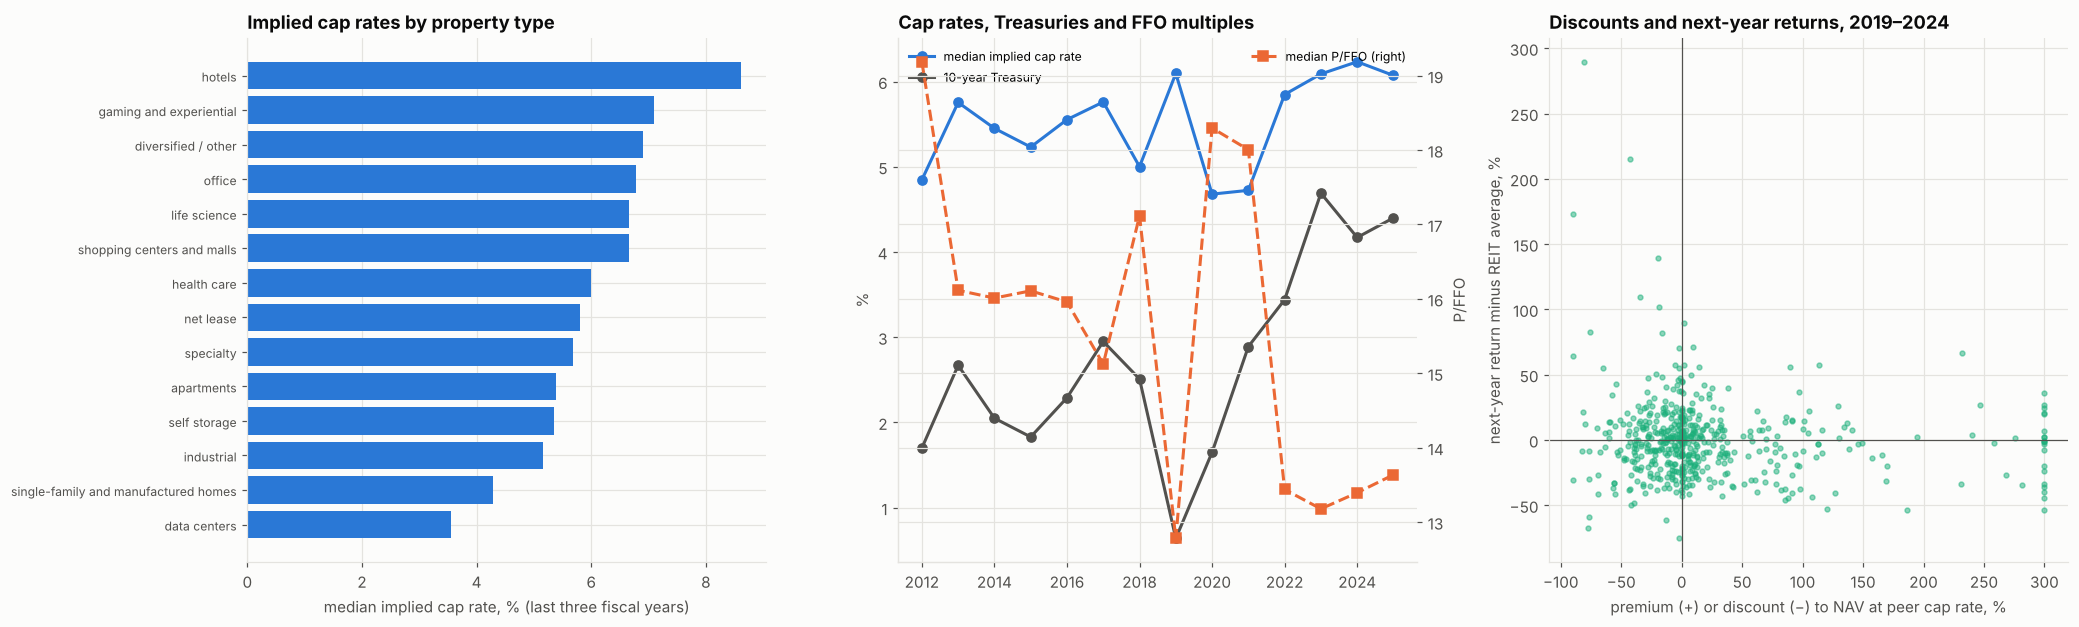

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.8))
a = ax[0]
b = BYT.sort_values("implied_cap_rate")
a.barh(b.index, b.implied_cap_rate * 100, color=PALETTE[0])
a.set_xlabel("median implied cap rate, % (last three fiscal years)")
a.set_title("Implied cap rates by property type")
a.tick_params(axis="y", labelsize=8)
a = ax[1]
a.plot(
    BYY.index,
    BYY.implied_cap_rate * 100,
    "o-",
    color=PALETTE[0],
    label="median implied cap rate",
)
a.plot(
    BYY.index,
    BYY["10-year Treasury (April)"] * 100,
    "o-",
    color=INK_2,
    label="10-year Treasury",
)
a2 = a.twinx()
a2.plot(
    BYY.index, BYY.P_FFO, "s--", color=PALETTE[1], label="median P/FFO (right)"
)
a.set_ylabel("%")
a2.set_ylabel("P/FFO")
a.set_title("Cap rates, Treasuries and FFO multiples")
a.legend(fontsize=8, loc="upper left")
a2.legend(fontsize=8, loc="upper right")
a = ax[2]
a.scatter(
    D.loc[T.index, "prem"] * 100,
    T.ret_rel * 100,
    s=10,
    color=PALETTE[2],
    alpha=0.5,
)
a.axhline(0, color=INK_2, lw=0.8)
a.axvline(0, color=INK_2, lw=0.8)
a.set_xlabel("premium (+) or discount (−) to NAV at peer cap rate, %")
a.set_ylabel("next-year return minus REIT average, %")
a.set_title(
    f"Discounts and next-year returns, {TRAIN_LAST + 1}–{int(Dz.fy.max())}"
)
fig.tight_layout()
save_fig(fig, "01_reit_valuation")
plt.show()

In [8]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "P/FFO vs implied cap rate, latest fiscal year",
        "Rank IC with next-year returns, test years",
    ),
)
L = V[V.fy == V.fy.max()]
for i, (k, g) in enumerate(L.groupby("type")):
    dash.add_trace(
        go.Scatter(
            x=g.cap_rate * 100,
            y=g["P/FFO"],
            mode="markers",
            name=k,
            text=g.Name,
            marker=dict(color=PALETTE[i % len(PALETTE)], size=8),
            hovertemplate=(
                "%{text}<br>cap %{x:.1f}%<br>P/FFO %{y:.1f}<extra></extra>"
            ),
        ),
        1,
        1,
    )
dash.add_trace(
    go.Bar(
        x=IC.index,
        y=IC["mean rank IC"],
        marker_color=PALETTE[3],
        showlegend=False,
    ),
    1,
    2,
)
dash.update_xaxes(title_text="implied cap rate, %", row=1, col=1)
dash.update_yaxes(title_text="P/FFO", row=1, col=1)
dash.update_layout(
    height=560,
    width=1450,
    template="simple_white",
    title="REIT valuation: FFO, AFFO, cap rates and NAV",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 7. Reading the results and limitations

**The sample.** 121 of the 122 REITs in the ETF have 10-K data in SEC company facts, giving 1,576 REIT-years from 2012 to 2025. FFO can be built for almost every REIT-year, and the EBITDAre proxy for NOI for 80–90% of them. AFFO is available for only about a third, because few REITs tag recurring capital spending separately in XBRL.

**Multiples and cap rates line up by property type.** In the latest three fiscal years:

| Property type | Median P/FFO | Implied cap rate |
|---|---|---|
| Data centers | 29× | 3.5% |
| Single-family and manufactured homes | 21× | 4.3% |
| Industrial | 15× | 5.2% |
| Apartments | 16× | 5.4% |
| Net lease | 15× | 5.8% |
| Health care | 14× | 6.0% |
| Shopping centers and malls | 12× | 6.7% |
| Office | 9× | 6.8% |
| Hotels | 8× | 8.6% |

The ranking is the textbook one. Sectors with steady, growing cash flows (data centers, housing, logistics) trade at low cap rates and high multiples. Sectors with cyclical or structurally challenged income (hotels, offices since remote work) trade at high cap rates and single-digit multiples.

**Cap rates moved with rates, but only partly.** The median implied cap rate rose from 4.7% (April 2021–22) to 6.1–6.2% (2024–26) as the ten-year Treasury went from 1.7–2.9% to 4.2–4.7%. Median P/FFO fell from 18× to 13–14×. The spread between cap rates and Treasuries shrank from about 3 points in 2012–17 to 1.4–2.1 points since 2023. Real estate absorbed part of the rate shock through compressed spreads rather than full repricing, a sign of expected rent growth or of slow-moving property valuations.

**NAV at peer cap rates: wide dispersion within types.** Valuing each REIT's EBITDAre at its type's median cap rate gives a premium or discount to NAV with a median near zero by construction, but a wide range:
- **Spread within types:** the 10th to 90th percentile is −34% to +230% for apartments and −41% to +183% for offices.
- **Leverage:** with debt at half of assets, a small difference in cap rate becomes a large difference in equity value.
- **Deep discounts:** in fiscal 2025 they are distressed or out-of-favour names (Braemar Hotels, Industrial Logistics Properties, Net Lease Office Properties, CBL, Douglas Emmett).
- **Premiums:** data centers, valued here at the all-REIT median because the type has only two members, show a premium that reflects their growth.

**Do cheap REITs outperform?** On valuation dates from 2019 to 2024, with returns over the following twelve months:

| Signal or model | Mean rank IC | Years with IC > 0 | Top minus bottom quintile, % a year |
|---|---|---|---|
| NAV premium (higher = more expensive) | −0.07 | 2 of 6 | −9.9 |
| FFO yield | 0.10 | 4 of 6 | +8.6 |
| AFFO yield | 0.05 | 5 of 6 | +3.0 |
| Implied cap rate | 0.13 | 4 of 6 | +16.7 |
| Linear model (all signals) | −0.08 | 3 of 6 | −9.4 |
| LightGBM (all signals) | −0.09 | 2 of 6 | −3.9 |

Each simple value signal points the right way:
- **Cap rate:** REITs with high implied cap rates beat those with low ones by about 17 points a year on average.
- **FFO yield:** high FFO yields beat low ones by about 9 points.
- **NAV premium:** REITs at large premiums to NAV lagged.

This matches the evidence that REIT prices revert towards underlying property values. But the dispersion is large, six test years is a short sample, and in two of them the relation reversed.

The combined models fail out of sample. Trained on 2012–2018, a period of falling rates when growth sectors re-rated upwards, they learned relations that turned in 2019–2024, a period that included Covid and the rate shock. With about 500 training REIT-years, adding signals and non-linearity adds noise rather than information. A single, economically motivated value signal is more robust here than a model.

**Limits.**
- **Universe:** today's ETF members are used throughout, so REITs that were acquired or delisted are missing (survivorship).
- **NOI proxy:** EBITDAre stands in for property-level NOI, and AFFO is available for only a third of REIT-years.
- **NAV method:** peer-median cap rates are not appraisals; true NAVs use private-market cap rates from transactions, which are not public.
- **Property types:** classified by ticker for the larger REITs and by name for the rest; types with fewer than three members use the all-REIT median.

In [9]:
V.to_csv(OUT_DIR / "reit_valuation_panel.csv", index=False)
BYT.to_csv(OUT_DIR / "multiples_by_property_type.csv")
BYY.to_csv(OUT_DIR / "multiples_by_year.csv")
IC.to_csv(OUT_DIR / "return_prediction_test.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_reit_valuation.png, dashboard.html, dashboard.png, multiples_by_property_type.csv, multiples_by_year.csv, reit_valuation_panel.csv, return_prediction_test.csv


## References

- BlackRock iShares. iShares Core U.S. REIT ETF (USRT), fund holdings. https://www.ishares.com/us/products/239544/
- U.S. Securities and Exchange Commission. EDGAR XBRL company facts API. https://www.sec.gov/search-filings/edgar-application-programming-interfaces
- Federal Reserve Bank of St. Louis. FRED: Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity (DGS10). https://fred.stlouisfed.org/series/DGS10
- Yahoo Finance. Historical prices. https://finance.yahoo.com/
- CFA Institute. CFA Program Level II curriculum, Equity Valuation: Private Real Estate Investments and Publicly Traded Real Estate Securities.
- Nareit (2018). Nareit Funds from Operations White Paper, 2018 Restatement. https://www.reit.com/data-research/research/nareit-research/nareit-funds-operations-white-paper-2018-restatement
- Clayton, J., & MacKinnon, G. (2003). The relative importance of stock, bond and real estate factors in explaining REIT returns. *Journal of Real Estate Finance and Economics*, 27(1), 39–60.
- Capozza, D. R., & Seguin, P. J. (1999). Focus, transparency and value: The REIT evidence. *Real Estate Economics*, 27(4), 587–619.
- Barkham, R., & Geltner, D. (1995). Price discovery in American and British property markets. *Real Estate Economics*, 23(1), 21–44.
- Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, 30.